In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/METABRIC_RNA_Mutation.csv')

C:\Users\DANISH LAPTOP\AppData\Local\Temp\ipykernel_17072\591033886.py:1: DtypeWarning: Columns (0: rasgef1b_mut, 1: hras_mut, 2: smarcb1_mut, 3: siah1_mut) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/METABRIC_RNA_Mutation.csv')


In [4]:
df.head()

,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df.shape

(1904, 693)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1904 entries, 0 to 1903
Columns: 693 entries, patient_id to siah1_mut
dtypes: float64(498), int64(5), object(4), str(186)
memory usage: 10.1+ MB


In [7]:
df.describe()

,patient_id,age_at_diagnosis,chemotherapy,cohort,neoplasm_histologic_grade,hormone_therapy,lymph_nodes_examined_positive,mutation_count,nottingham_prognostic_index,overall_survival_months,...,srd5a1,srd5a2,srd5a3,st7,star,tnk2,tulp4,ugt2b15,ugt2b17,ugt2b7
count,1904.000000,1904.000000,1904.000000,1904.000000,1832.000000,1904.000000,1904.000000,1859.000000,1904.000000,1904.000000,...,1.904000e+03,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03,1.904000e+03,1.904000e+03,1904.000000,1.904000e+03
mean,3921.982143,61.087054,0.207983,2.643908,2.415939,0.616597,2.002101,5.697687,4.033019,125.121324,...,4.726891e-07,-3.676471e-07,-9.453782e-07,-1.050420e-07,-0.000002,3.676471e-07,4.726891e-07,7.878151e-07,0.000000,3.731842e-18
std,2358.478332,12.978711,0.405971,1.228615,0.650612,0.486343,4.079993,4.058778,1.144492,76.334148,...,1.000263e+00,1.000262e+00,1.000262e+00,1.000263e+00,1.000262,1.000264e+00,1.000262e+00,1.000263e+00,1.000262,1.000262e+00
min,0.000000,21.930000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,-2.120800e+00,-3.364800e+00,-2.719400e+00,-4.982700e+00,-2.981700,-3.833300e+00,-3.609300e+00,-1.166900e+00,-2.112600,-1.051600e+00
25%,896.500000,51.375000,0.000000,1.000000,2.000000,0.000000,0.000000,3.000000,3.046000,60.825000,...,-6.188500e-01,-6.104750e-01,-6.741750e-01,-6.136750e-01,-0.632900,-6.664750e-01,-7.102000e-01,-5.058250e-01,-0.476200,-7.260000e-01
50%,4730.500000,61.770000,0.000000,3.000000,3.000000,1.000000,0.000000,5.000000,4.042000,115.616667,...,-2.456500e-01,-4.690000e-02,-1.422500e-01,-5.175000e-02,-0.026650,7.000000e-04,-2.980000e-02,-2.885500e-01,-0.133400,-4.248000e-01
75%,5536.250000,70.592500,0.000000,3.000000,3.000000,1.000000,2.000000,7.000000,5.040250,184.716667,...,3.306000e-01,5.144500e-01,5.146000e-01,5.787750e-01,0.590350,6.429000e-01,5.957250e-01,6.022500e-02,0.270375,4.284000e-01
max,7299.000000,96.290000,1.000000,5.000000,3.000000,1.000000,45.000000,80.000000,6.360000,355.200000,...,6.534900e+00,1.027030e+01,6.329000e+00,4.571300e+00,12.742300,3.938800e+00,3.833400e+00,1.088490e+01,12.643900,3.284400e+00


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing['Missing Count'] > 0].sort_values('Missing Percentage', ascending = False)

missing

,Missing Count,Missing Percentage
tumor_stage,501,26.313025
3-gene_classifier_subtype,204,10.714286
primary_tumor_laterality,106,5.567227
neoplasm_histologic_grade,72,3.781513
cellularity,54,2.836134
mutation_count,45,2.363445
er_status_measured_by_ihc,30,1.575630
type_of_breast_surgery,22,1.155462
tumor_size,20,1.050420
cancer_type_detailed,15,0.787815


In [10]:
[c for c in df.columns if any(word in c.lower()
                             for word in ['survival', 'death', 'status', 'event'])]


['er_status_measured_by_ihc',
 'er_status',
 'her2_status_measured_by_snp6',
 'her2_status',
 'overall_survival_months',
 'overall_survival',
 'pr_status',
 'death_from_cancer']

In [11]:
df['overall_survival'].value_counts()

overall_survival
0    1103
1     801
Name: count, dtype: int64

In [14]:
df['overall_survival'].value_counts(normalize=True)*100

overall_survival
0    57.930672
1    42.069328
Name: proportion, dtype: float64

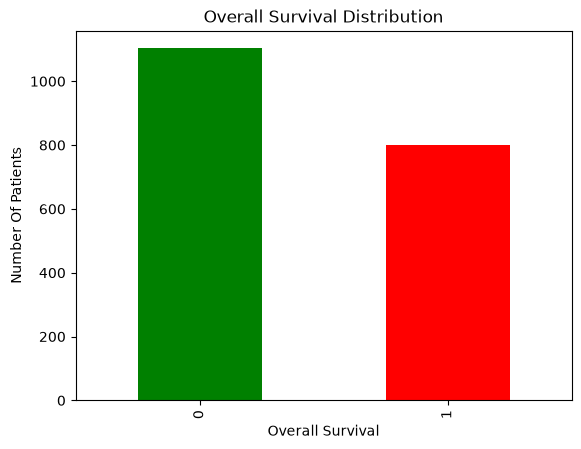

In [15]:
df['overall_survival'].value_counts().plot(kind='bar', color=['green', 'red'])

plt.title('Overall Survival Distribution')
plt.xlabel('Overall Survival')
plt.ylabel('Number Of Patients')
plt.show()

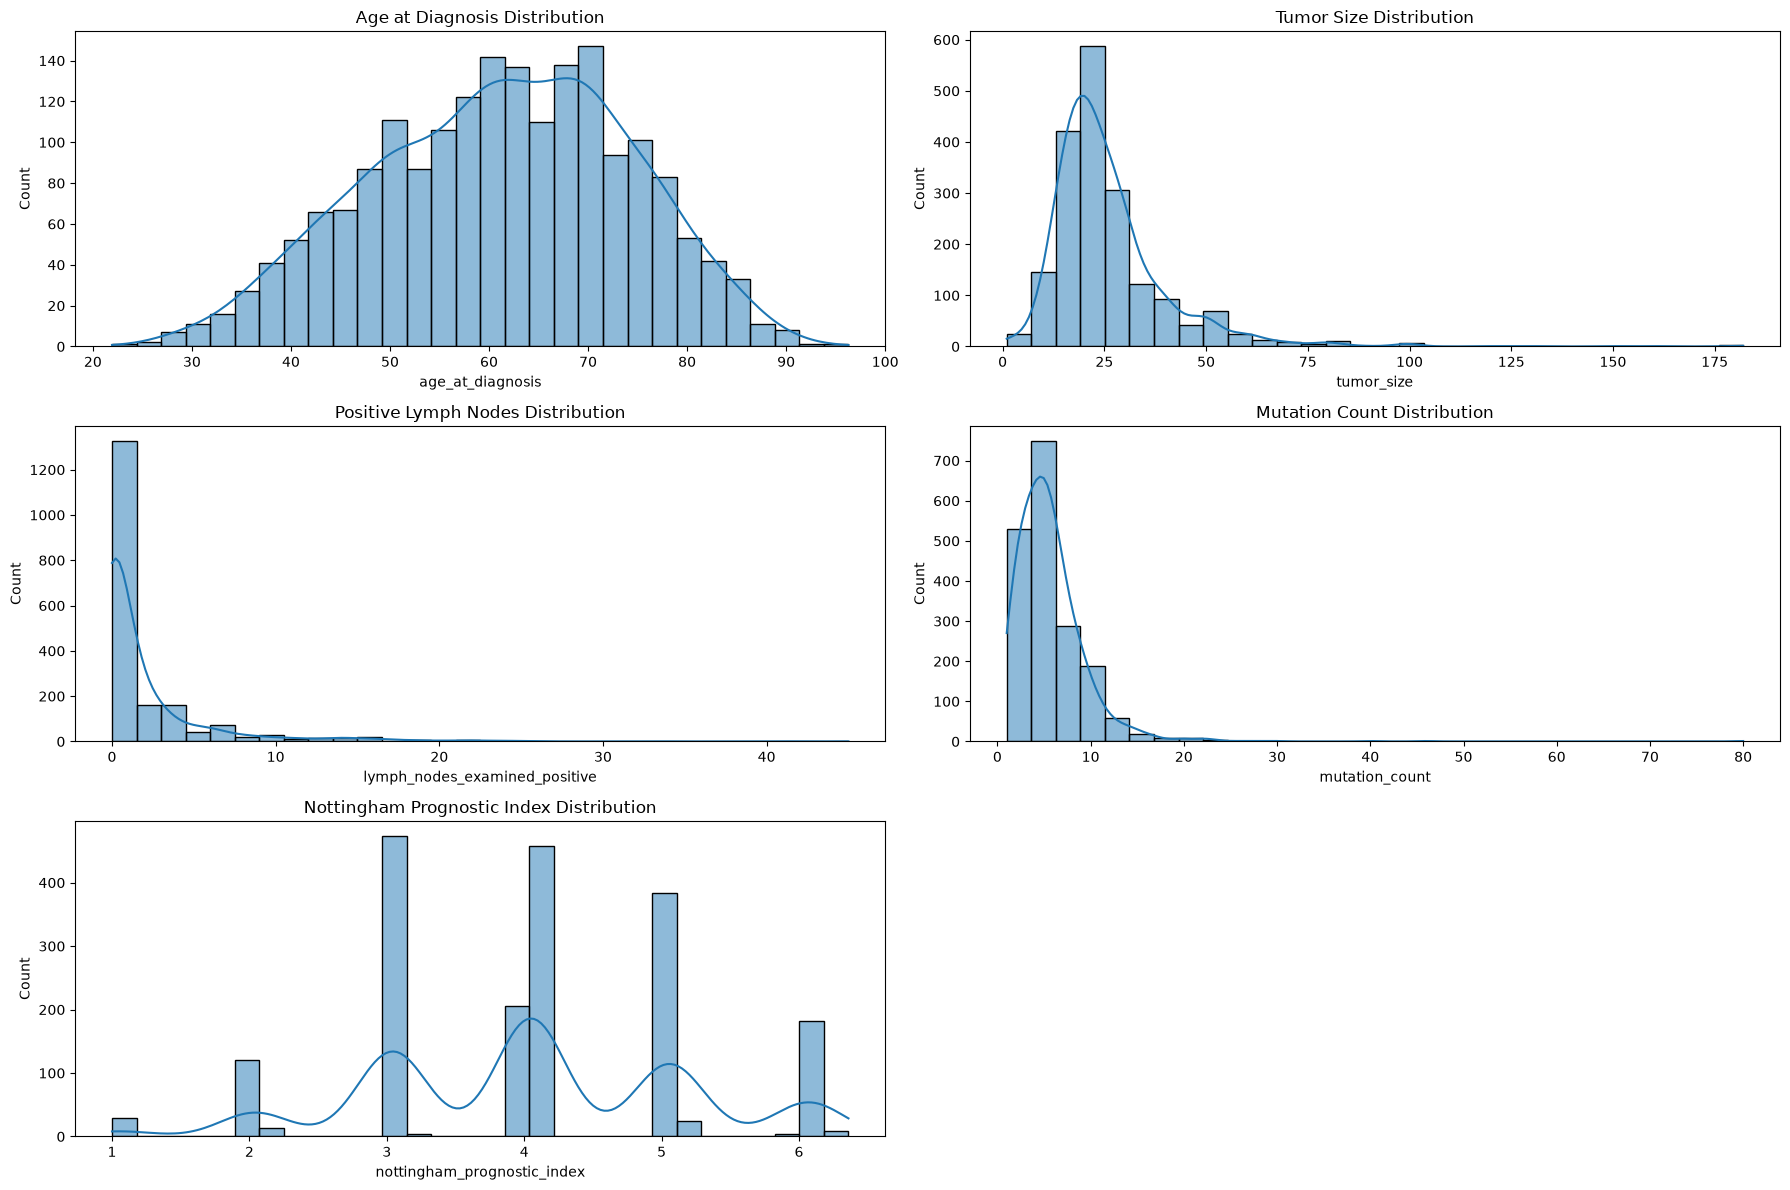

In [25]:
numerical_cols = [
    'age_at_diagnosis',
    'tumor_size',
    'lymph_nodes_examined_positive',
    'mutation_count',
    'nottingham_prognostic_index'
]

plt.figure(figsize = (18, 12))

plt.subplot(3, 2, 1)
sns.histplot(df['age_at_diagnosis'], bins = 30, kde = True)
plt.title('Age at Diagnosis Distribution')

plt.subplot(3, 2, 2)
sns.histplot(df['tumor_size'], bins=30, kde=True)
plt.title('Tumor Size Distribution')

plt.subplot(3, 2, 3)
sns.histplot(df['lymph_nodes_examined_positive'], bins=30, kde=True)
plt.title('Positive Lymph Nodes Distribution')

plt.subplot(3, 2, 4)
sns.histplot(df['mutation_count'], bins=30, kde=True)
plt.title('Mutation Count Distribution')

plt.subplot(3, 2, 5)
sns.histplot(df['nottingham_prognostic_index'], bins=30, kde=True)
plt.title('Nottingham Prognostic Index Distribution')

plt.tight_layout()
plt.show()

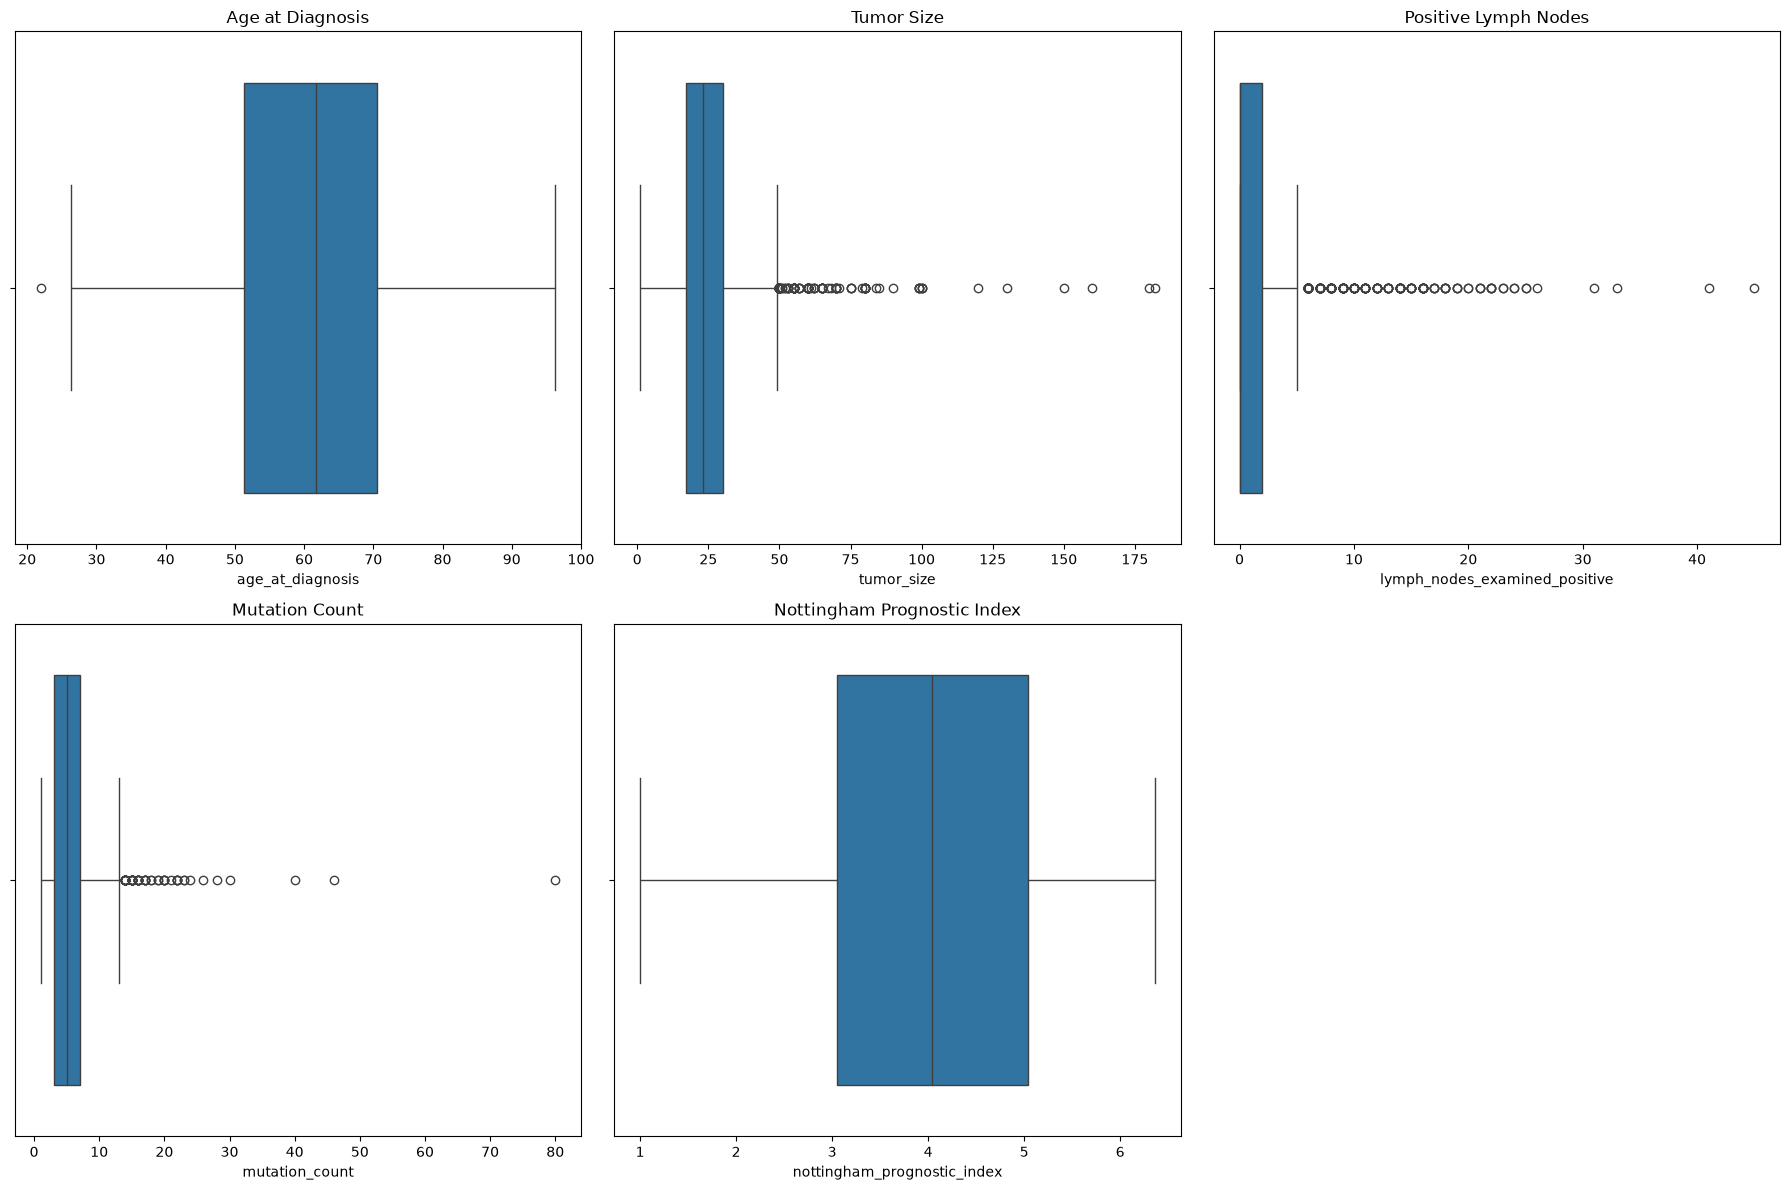

In [30]:
plt.figure(figsize=(18, 12))

plt.subplot(2, 3, 1)
sns.boxplot(x=df['age_at_diagnosis'])
plt.title('Age at Diagnosis')

plt.subplot(2, 3, 2)
sns.boxplot(x=df['tumor_size'])
plt.title('Tumor Size')

plt.subplot(2, 3, 3)
sns.boxplot(x=df['lymph_nodes_examined_positive'])
plt.title('Positive Lymph Nodes')

plt.subplot(2, 3, 4)
sns.boxplot(x=df['mutation_count'])
plt.title('Mutation Count')

plt.subplot(2, 3, 5)
sns.boxplot(x=df['nottingham_prognostic_index'])
plt.title('Nottingham Prognostic Index')

plt.tight_layout()
plt.show()

In [ ]:
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    Upper_limit = Q3 + 1.5 * IQR
    Lower_limit = Q1 - 1.5 * IQR

    outliers = df[(df[col] < Lower_limit) | (df[col] > Upper_limit)]
    
    print(col)
    print("Lower limit:", Lower_limit)
    print("Upper limit:", Upper_limit)
    print("Outliers:", len(outliers))
    print()

    

age_at_diagnosis
Lower limit: 22.54875
Upper limit: 99.41875
Outliers: 1

tumor_size
Lower limit: -2.5
Upper limit: 49.5
Outliers: 142

lymph_nodes_examined_positive
Lower limit: -3.0
Upper limit: 5.0
Outliers: 210

mutation_count
Lower limit: -3.0
Upper limit: 13.0
Outliers: 62

nottingham_prognostic_index
Lower limit: 0.054625000000000146
Upper limit: 8.031625
Outliers: 0



In [32]:
leakage_cols = [
    'patient_id',
    'overall_survival_months',
    'death_from_cancer'
]

df = df.drop(columns=leakage_cols)

df.shape

(1904, 690)

In [33]:
x = df.drop(columns=['overall_survival'])
y = df['overall_survival']

print("X shape:", x.shape)
print("Y shape:", y.shape)

X shape: (1904, 689)
Y shape: (1904,)


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify = y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (1523, 689)
Testing data: (381, 689)


In [35]:
missing_train = X_train.isnull().sum()

missing_train = missing_train[missing_train > 0].sort_values(ascending=False)

missing_train

tumor_stage                       406
3-gene_classifier_subtype         166
primary_tumor_laterality           85
neoplasm_histologic_grade          58
cellularity                        35
mutation_count                     34
er_status_measured_by_ihc          18
type_of_breast_surgery             14
tumor_size                         13
cancer_type_detailed               12
tumor_other_histologic_subtype     12
oncotree_code                      12
dtype: int64

In [36]:
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns

categorical_features = X_train.select_dtypes(include=['object', 'string']).columns

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nCategorical Columns:")
print(categorical_features.tolist())

Numerical Features: 500
Categorical Features: 189

Categorical Columns:
['type_of_breast_surgery', 'cancer_type', 'cancer_type_detailed', 'cellularity', 'pam50_+_claudin-low_subtype', 'er_status_measured_by_ihc', 'er_status', 'her2_status_measured_by_snp6', 'her2_status', 'tumor_other_histologic_subtype', 'inferred_menopausal_state', 'integrative_cluster', 'primary_tumor_laterality', 'oncotree_code', 'pr_status', '3-gene_classifier_subtype', 'pik3ca_mut', 'tp53_mut', 'muc16_mut', 'ahnak2_mut', 'kmt2c_mut', 'syne1_mut', 'gata3_mut', 'map3k1_mut', 'ahnak_mut', 'dnah11_mut', 'cdh1_mut', 'dnah2_mut', 'kmt2d_mut', 'ush2a_mut', 'ryr2_mut', 'dnah5_mut', 'herc2_mut', 'pde4dip_mut', 'akap9_mut', 'tg_mut', 'birc6_mut', 'utrn_mut', 'tbx3_mut', 'col6a3_mut', 'arid1a_mut', 'lama2_mut', 'notch1_mut', 'cbfb_mut', 'ncor2_mut', 'col12a1_mut', 'col22a1_mut', 'pten_mut', 'akt1_mut', 'atr_mut', 'thada_mut', 'ncor1_mut', 'stab2_mut', 'myh9_mut', 'runx1_mut', 'nf1_mut', 'map2k4_mut', 'ros1_mut', 'lamb3_mut'

## EDA Summary

- Dataset contains 1,904 patients and 693 features.
- No duplicate rows were identified.
- Overall survival classes are moderately balanced.
- Tumor stage contains the highest missingness.
- Tumor size, positive lymph nodes, and mutation count show strongly right-skewed distributions and multiple IQR-based extreme observations.
- Extreme clinical observations were retained because they may represent genuine patient characteristics rather than data errors.